# Two-level MOT loading parameter scans

Four independent sweeps; raw/effective saturation reuse the same power data. All fixed settings appear on each plot. Intervals are pointwise 95% Student-t across independent direction discs. The pilot is excluded. Run the cells again to refresh an ongoing campaign.

Capture spectra and per-disc counts are retained so temperature can be changed without new trajectories. Rb-87 partial pressure stays fixed; number density is recomputed as p/(k_B T). The spectra describe the specified finite 15 mm launch aperture and launch plane.

In [ ]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'pmot').is_dir())
sys.path.insert(0, str(root / 'src'))
from pmot.mot_simple import parameter_campaign as campaign
import matplotlib.pyplot as plt
temperature_k = 296.483
rb87_partial_pressure_torr = 1e-10
payloads = campaign.completed_payloads()
print(f'{len(payloads)}/{len(campaign.CONFIGURATIONS)} unique configurations complete')

In [ ]:
figures = campaign.plot_figures(payloads, temperature_k=temperature_k,
    pressure_torr=rb87_partial_pressure_torr, save=False)
plt.close('all')

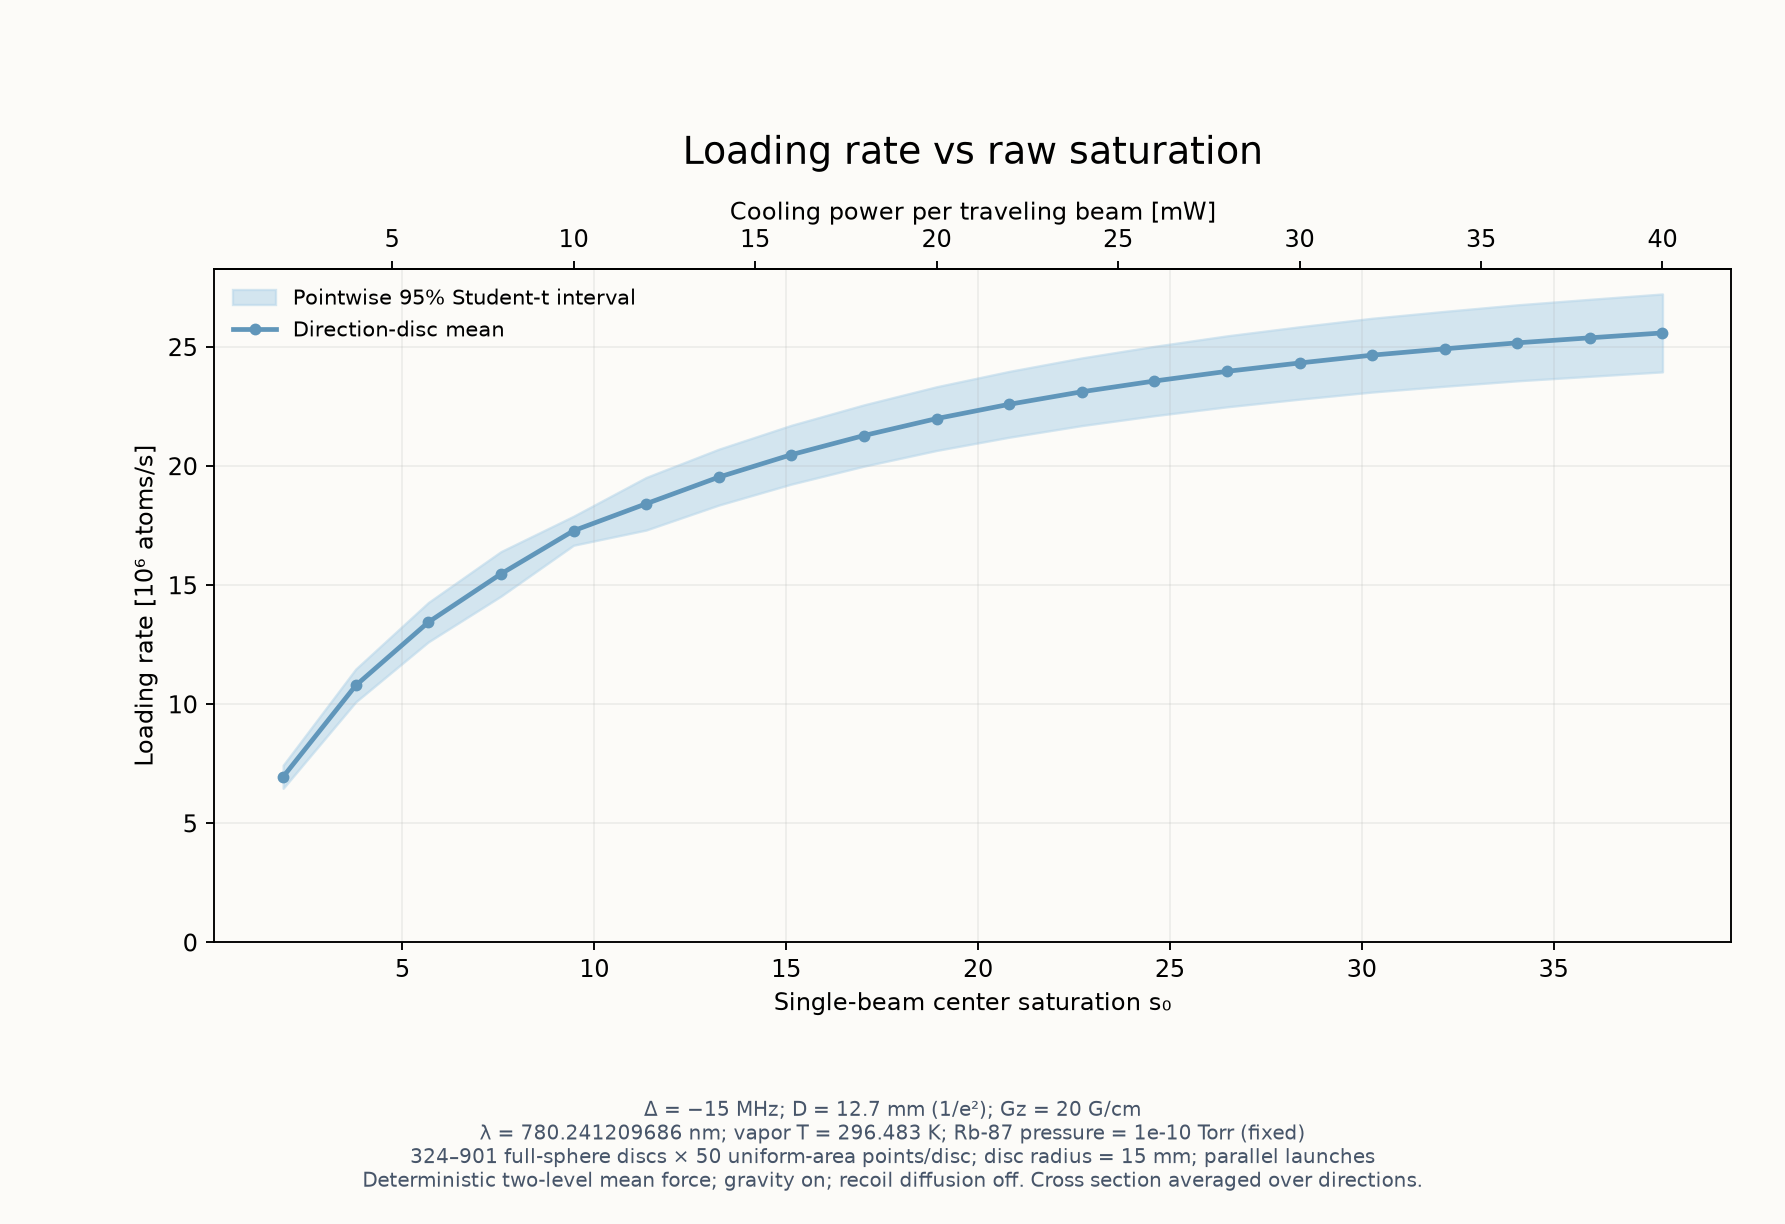

In [ ]:
display(figures[0])

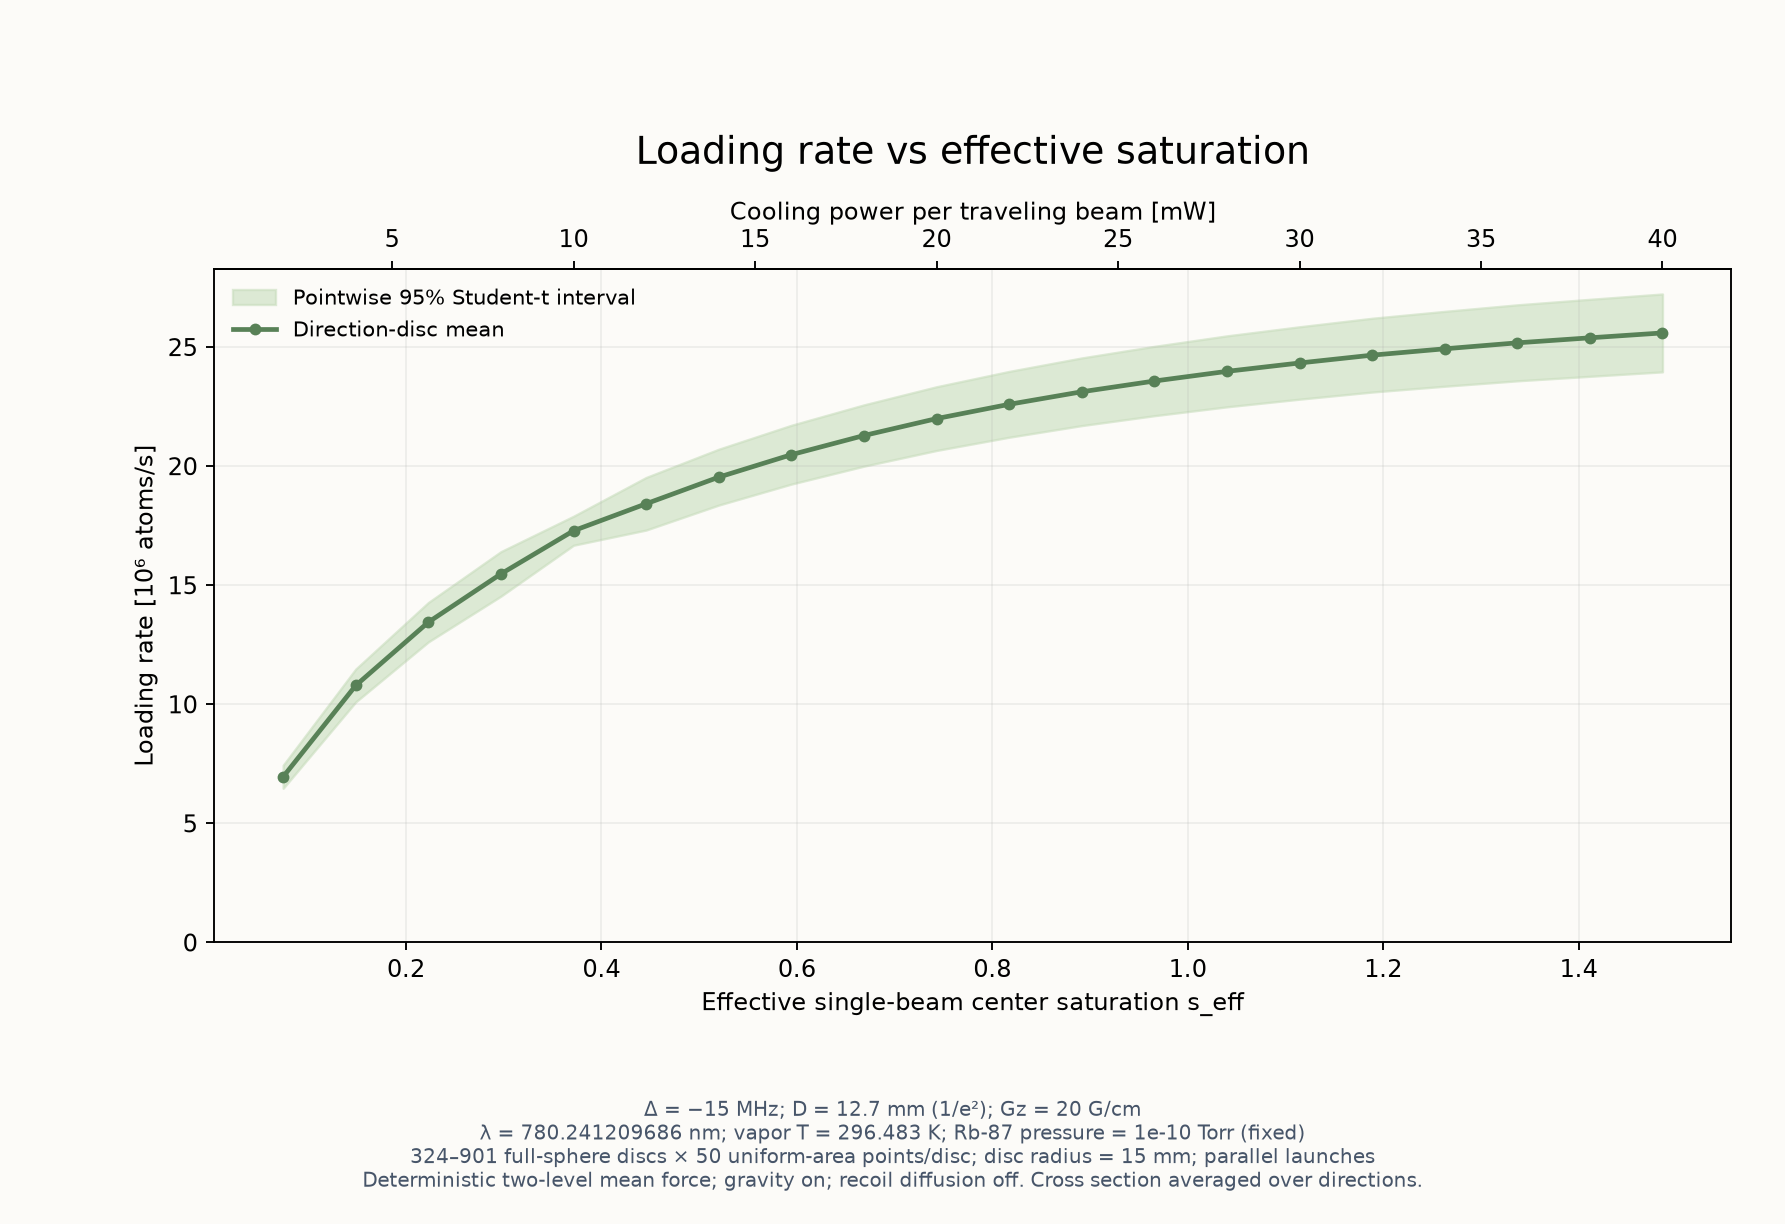

In [ ]:
display(figures[1])

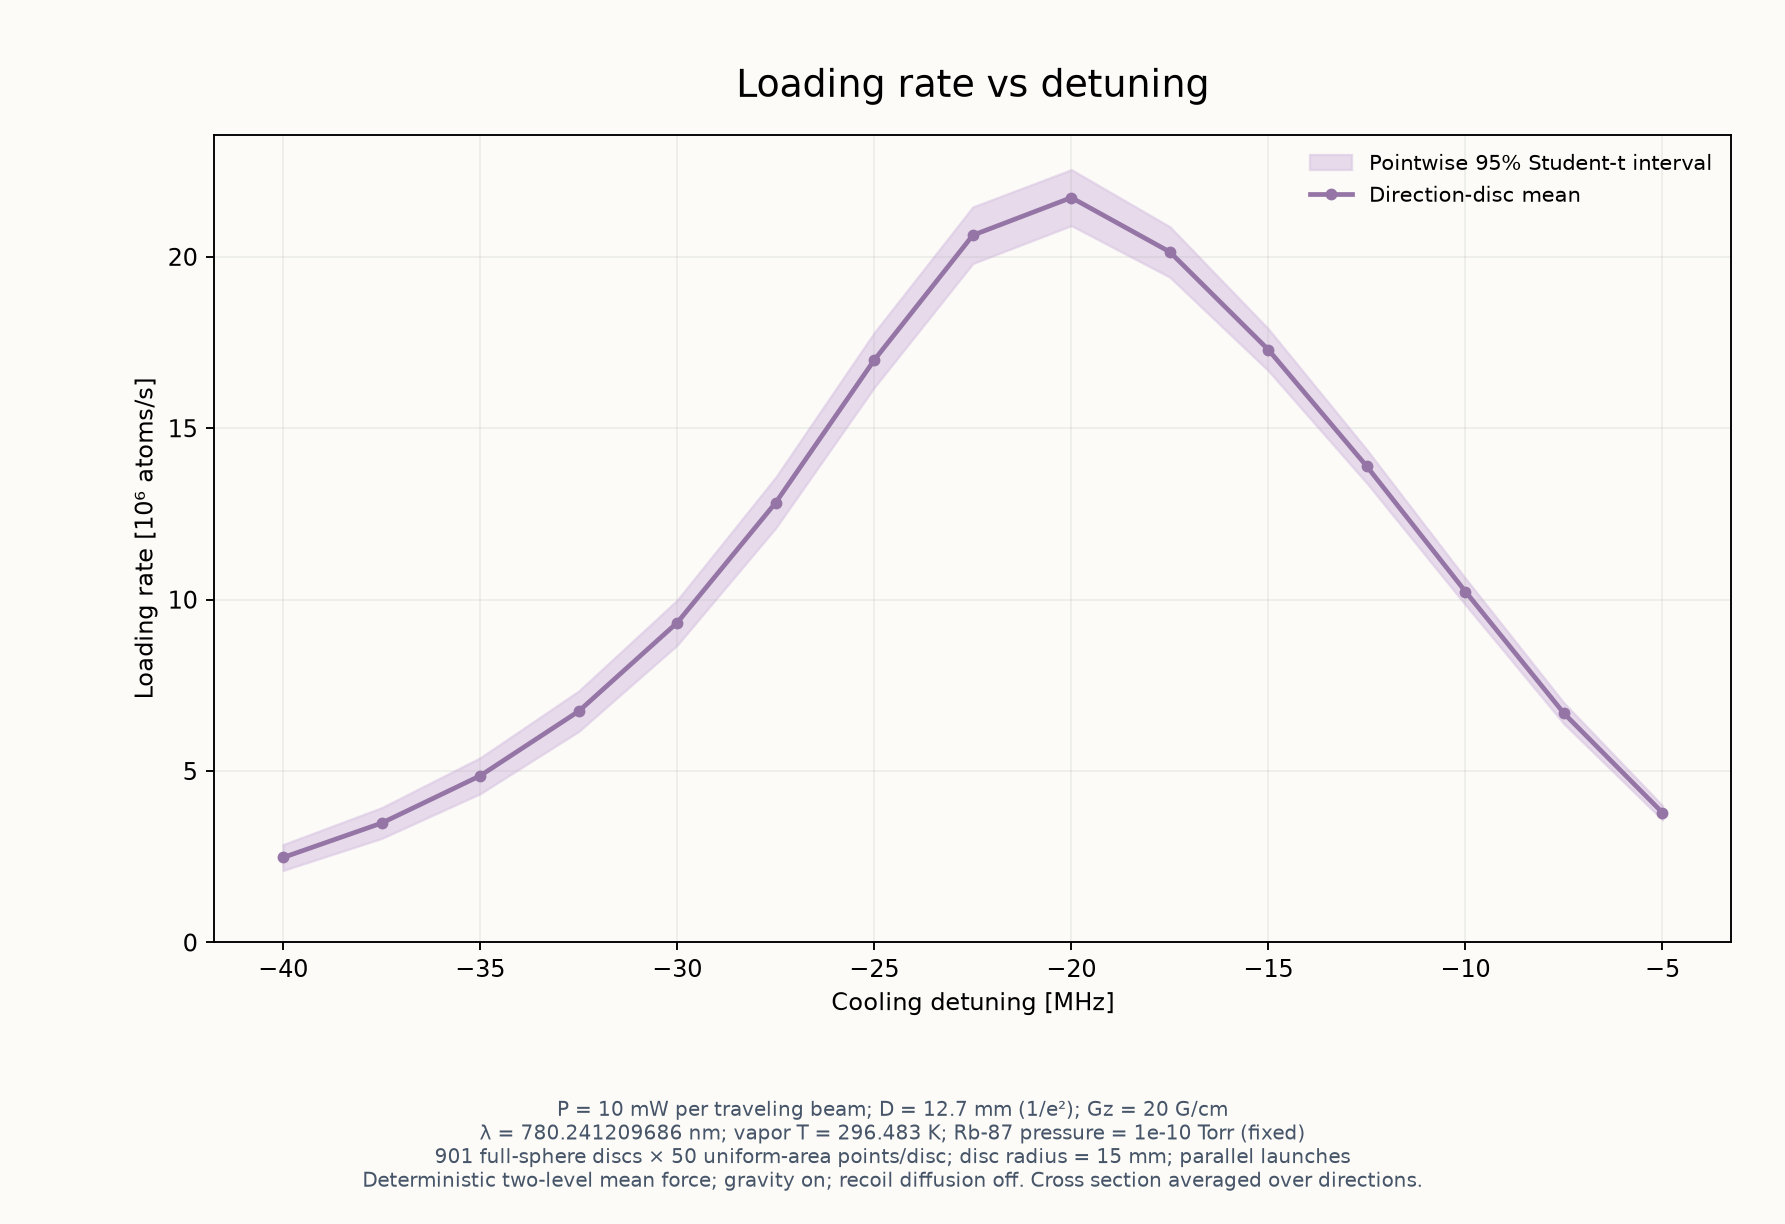

In [ ]:
display(figures[2])

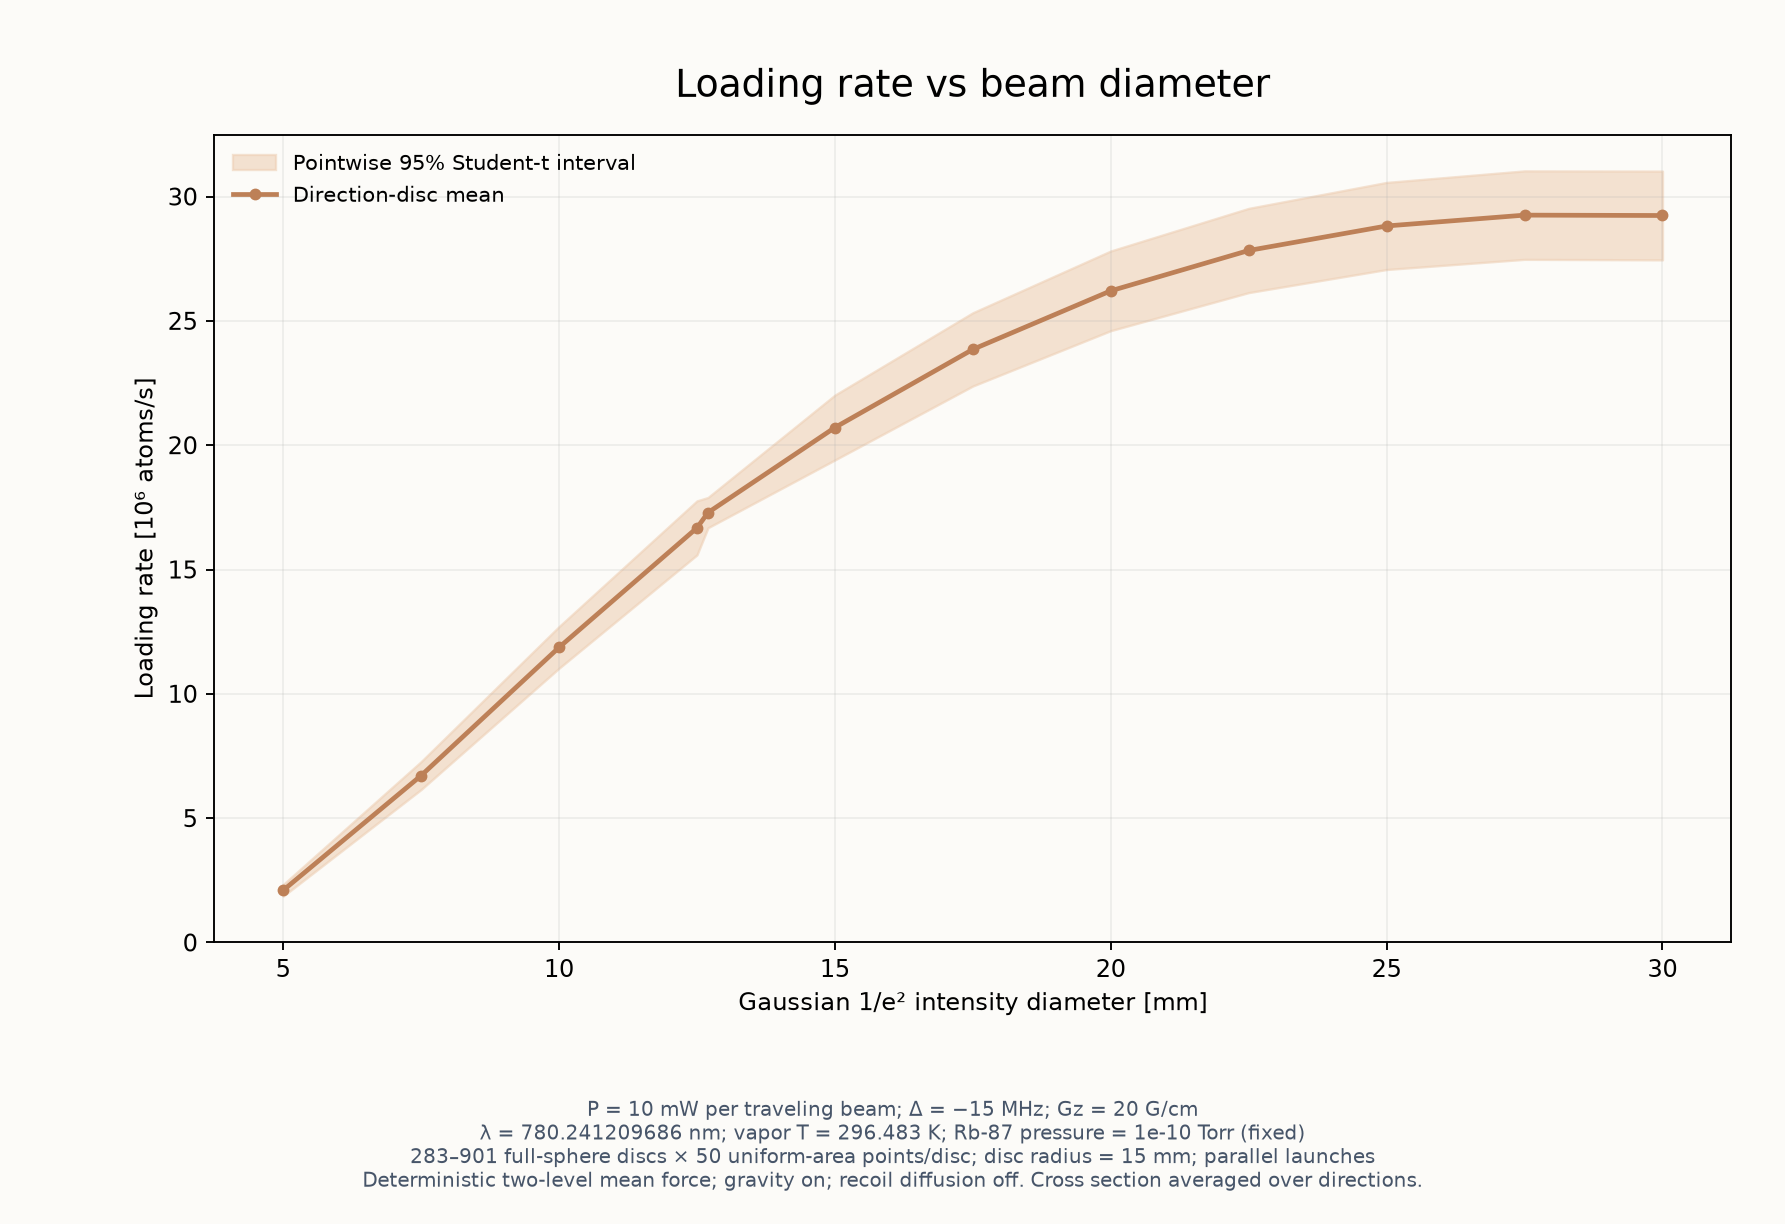

In [ ]:
display(figures[3])

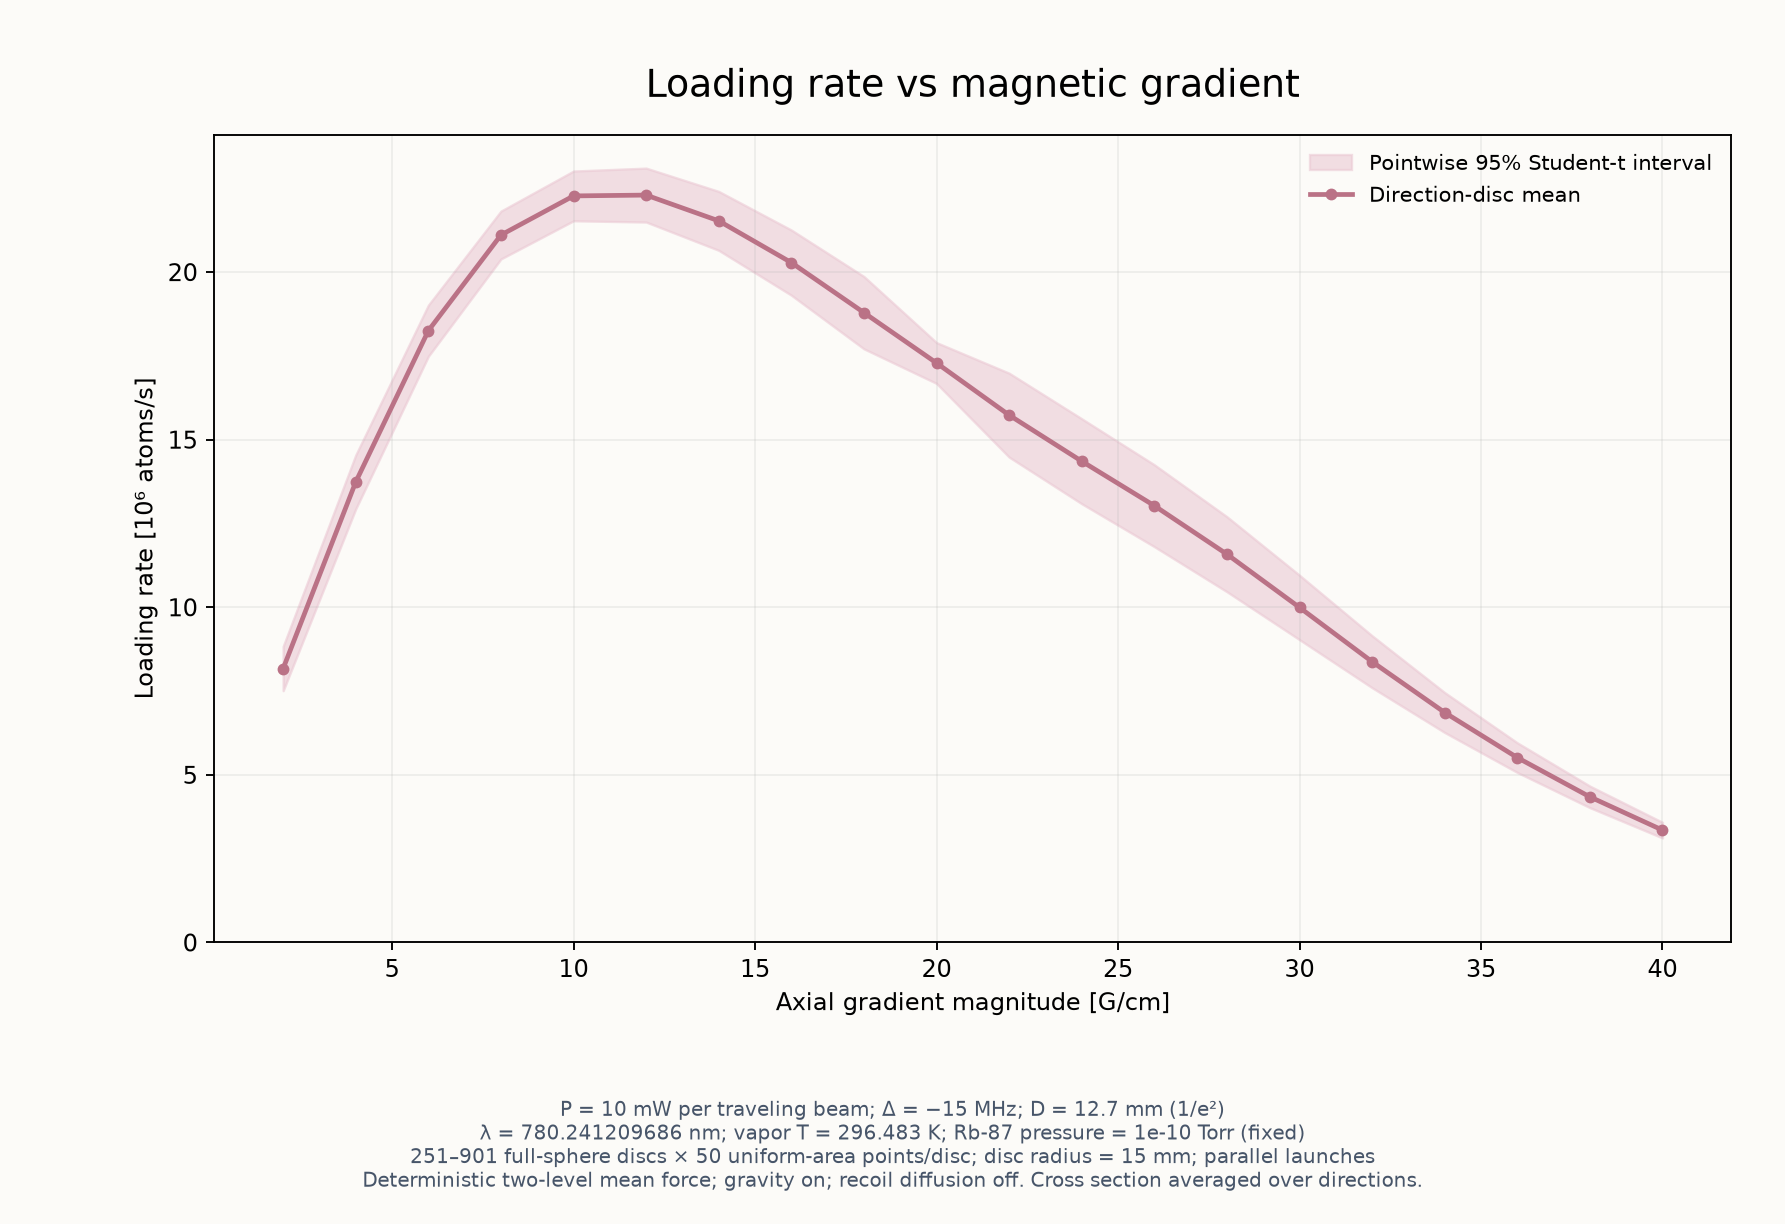

In [ ]:
display(figures[4])

In [ ]:
# Reload individual disc rates and uncertainties at the temperature above.
import pandas as pd
results = pd.DataFrame([{**campaign.config_record(i),
    **{k:v for k,v in campaign.reweight_counts(p, temperature_k, rb87_partial_pressure_torr).items()
       if k != 'disc_loading_rates_atoms_per_s'}} for i,p in payloads.items()])
results